# Three-state Potts model: simulation and findings

This notebook addresses the Statistical Physics assignment through Metropolis heating simulations, uncertainty estimates and configuration analysis. The accompanying background essay explains the sampling theory. Units are $J=k_B=1$; labels 0, 1 and 2 denote the assignment's three spin directions. Saved experiments supply the main figures; the Python demonstration and implementation checks run directly below. Reproduction commands are in the README.

## 1. Energy and update rule

For the three unit vectors, equal spins have dot product one and unequal spins have dot product minus one half. Therefore,

$$\mathbf{s}_i\cdot\mathbf{s}_j=(3\delta_{\sigma_i\sigma_j}-1)/2.$$

A lattice with coordination number $q$ has $qN/2$ bonds. Substituting the identity into the vector energy gives

$$E=-\frac{3J}{2}\sum_{\langle i,j\rangle}\delta_{\sigma_i\sigma_j}+\frac{JqN}{4}+\Gamma,
\qquad \boxed{\Gamma=-JqN/4}.$$

The constant cancels from energy changes. On a periodic square lattice, choose a site uniformly and propose either alternative state with equal probability. If the old and proposed states match different numbers of neighbours,

$$\Delta E=-\frac32(n_{\rm new}-n_{\rm old})-h(s_{{\rm new},x}-s_{{\rm old},x}),
\qquad a=\min(1,e^{-\Delta E/T}).$$

Rejected proposals retain the current state. One sweep contains $L^2$ random-site attempts. The readable Python sampler and equivalent C++ kernel use this same rule.


In [1]:
import json
import platform
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
import reference_potts

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'font.size': 10})
colors = ['#2b669f', '#df8c38', '#80599c']
cmap = ListedColormap(colors)
tc = 1.5 / np.log(1 + np.sqrt(3))
# A small Python run demonstrates the interface; longer saved runs follow.
example = reference_potts.simulate([1.5], size=8, burn_sweeps=100,
                                   samples=200, sample_interval=1, seed=17)
print(f'Python demonstration: mean magnitude = {example["magnetisation"].mean():.3f}')


Python demonstration: mean magnitude = 0.791


## 2. Heating protocol and uncertainty

Each trajectory starts fully ordered at $T=0.60$, heats in increments of $0.075$ to $2.40$, and carries its final configuration into the next temperature. For every temperature, 500 sweeps are discarded and 500 measured. Eight independently seeded trajectories are repeated for each initial direction and $h=0,0.08,0.20$, principally at $L=24$.

We average the instantaneous magnitude $m=|N^{-1}\sum_i\mathbf{s}_i|$, rather than the magnitude of the averaged vector. Error bars are one standard error across run-level means. This accommodates within-run correlations without pretending every sweep is independent, but cannot detect a shared equilibration bias. Four times as many comparable independent runs should approximately halve the standard error.

The chosen sweep counts are a practical starting point; equilibrium must be checked for each regime.

## 3. Zero field: ordering and finite size

The three starting orientations give similar magnitude curves, consistent with their symmetry. The rapid decrease lies near the exact infinite-lattice critical temperature $T_c=(3/2)/\ln(1+\sqrt3)\approx1.49246$. The factor $3/2$ follows from this assignment's coupling. The known transition is continuous [1]; these rounded finite-lattice curves alone do not establish its order.

At $T=1.575$, the mean magnitudes are approximately 0.505, 0.292 and 0.180 for $L=12,24,36$. Larger lattices show a sharper crossover and smaller disordered-state residual magnitude. Near the transition, fluctuations and slow relaxation increase uncertainty: for the $L=24$ state-0 run, the SEM rises from 0.0013 at $T=1.275$ to 0.0327 at $T=1.50$. These bars do not themselves prove divergent susceptibility.


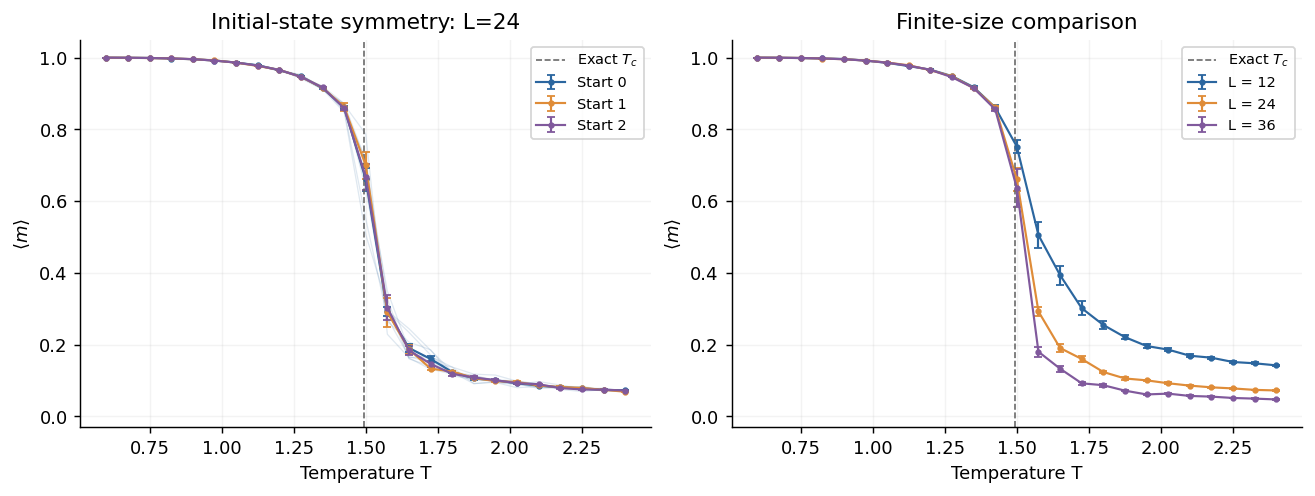

In [2]:
with np.load('results/simulations.npz') as data:
    temperatures = data['temperatures'].copy()
    runs = {name: data[name].copy() for name in data.files if name != 'temperatures'}

def mean_sem(values):
    return values.mean(axis=0), values.std(axis=0, ddof=1) / np.sqrt(len(values))

def draw_error(ax, values, label, color, ts=temperatures):
    mean, sem = mean_sem(values)
    ax.errorbar(ts, mean, yerr=sem, color=color, label=label,
                marker='o', ms=2.5, lw=1.2, capsize=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
for trajectory in runs['L24_h0_s0_m']:
    axes[0].plot(temperatures, trajectory, color=colors[0], alpha=.15, lw=.7)
for state, color in enumerate(colors):
    draw_error(axes[0], runs[f'L24_h0_s{state}_m'], f'Start {state}', color)
for size, color in zip((12, 24, 36), colors):
    draw_error(axes[1], runs[f'L{size}_h0_s0_m'], f'L = {size}', color)
for ax, title in zip(axes, ('Initial-state symmetry: L=24', 'Finite-size comparison')):
    ax.axvline(tc, color='.4', ls='--', lw=.9, label='Exact $T_c$')
    ax.set(title=title, xlabel='Temperature T', ylabel=r'$\langle m\rangle$', ylim=(-.03, 1.05))
    ax.grid(alpha=.15)
    ax.legend(fontsize=8)
plt.show()


## 4. Configurations: uniform, critical and disordered

The larger, fixed-temperature examples below show three characteristic geometries. Below $T_c$, almost all spins align. At $T_c$, irregular domains, holes and branches occur at multiple scales; the crop exposes finer structure. Above $T_c$, there is little global alignment, although neighbouring spins remain correlated.

Critical geometric clusters—connected nearest-neighbour sites with equal labels—have fractal scaling [2]. Our images illustrate that structure; they do not measure a fractal dimension. The low-temperature run starts ordered, while critical and high-temperature examples use random initial labels, following the original configuration experiment. These choices do not alter the ordered-start heating protocol.

The displayed runs were fixed by seed order. The critical image follows 8,000 discarded plus 2,000 measured sweeps; the high-temperature image follows 4,000 sweeps; the low-temperature image follows 2,001 sweeps. These are individual configurations, not ensemble averages.

Marko reports a geometric-cluster fractal dimension near 1.922 for this model; that published estimate is not fitted here. Critical geometry describes the transition region, not an additional equilibrium phase between ordered and disordered states. The enlarged region was fixed in advance, rather than selected for an especially intricate shape.


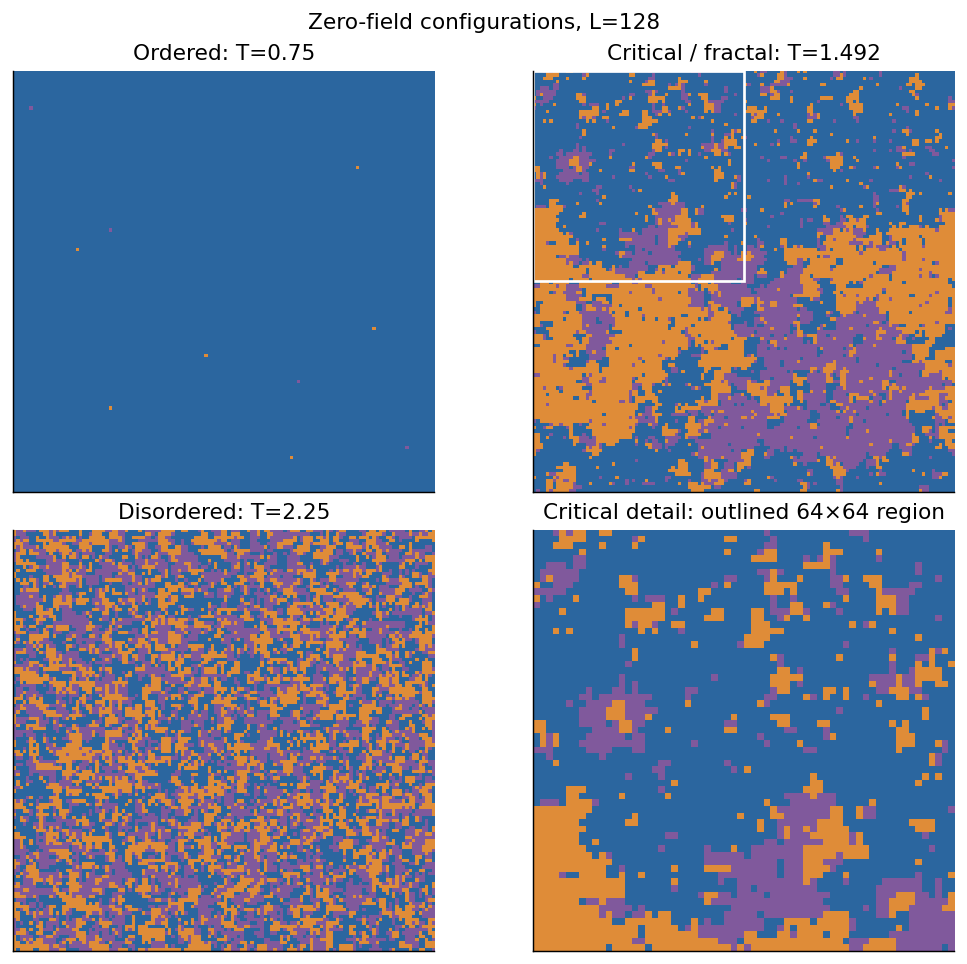

In [3]:
with np.load('results/critical_configurations.npz') as data:
    low_snapshot = data['low_snapshot'].copy()
    critical_ordered_means = data['critical_long_means'].copy()
with np.load('results/disorder_diagnostic.npz') as data:
    diagnostic = {name: data[name].copy() for name in data.files if name != 'metadata'}
critical = diagnostic['critical_random_snapshots'][0]
high = diagnostic['random_snapshots'][0]

fig, axes = plt.subplots(2, 2, figsize=(8, 7.3), constrained_layout=True)
images = [low_snapshot, critical, high, critical[:64, :64]]
titles = ['Ordered: T=0.75', f'Critical / fractal: T={tc:.3f}',
          'Disordered: T=2.25', 'Critical detail: outlined 64×64 region']
for ax, lattice, title in zip(axes.flat, images, titles):
    ax.imshow(lattice, cmap=cmap, vmin=0, vmax=2, interpolation='nearest')
    ax.set(title=title, xticks=[], yticks=[])
axes[0, 1].add_patch(Rectangle((-.5, -.5), 64, 64, edgecolor='white',
                               facecolor='none', linewidth=1.5))
fig.suptitle('Zero-field configurations, L=128')
plt.show()


## 5. Initialisation and equilibration

To test whether high-temperature patches simply reflect insufficient runtime, six ordered-start and six random-start trajectories were compared at $T=2.25$. Their final 2,000-sweep means give similar energies, magnitudes around 0.014–0.015, and equal-spin neighbour fractions near 0.520. Independent random spins would give one third. The surviving patches are consistent with finite-temperature local correlations; random initialisation need not produce independent noise after evolution.

Critical relaxation remains harder. Four ordered-start and four random-start runs give $0.549\pm0.076$ and $0.323\pm0.109$ after the longer protocol. These estimates leave substantial uncertainty about equilibration. Longer independent chains and autocorrelation checks are needed. Increasing discarded sweeps from 500 to 2,000, with 500 measurements unchanged, increases simulation work per temperature by a factor of 2.5.

At zero field, the equal-spin fraction follows directly from the energy per spin: there are two bonds per site, each contributing minus 1.5 when matched. This makes the energy a useful check beyond visual appearance. The original configuration function used a smaller coupling, so images at the same nominal temperature were effectively hotter and cannot be compared without conversion.


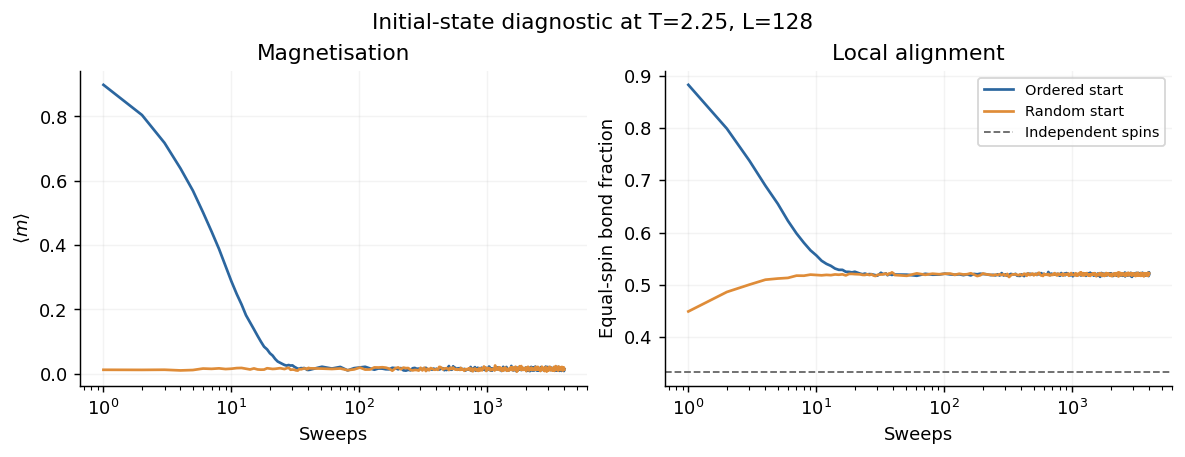

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
sweeps = np.arange(1, 4001)
shown = np.unique(np.r_[np.arange(40), np.arange(40, 4000, 10)])
for prefix, label, color in [('ordered', 'Ordered start', colors[0]),
                             ('random', 'Random start', colors[1])]:
    for ax, values in zip(axes, (diagnostic[f'{prefix}_m'],
                                -diagnostic[f'{prefix}_energy'] / 3)):
        ax.plot(sweeps[shown], values.mean(axis=0)[shown], color=color, label=label)
for ax, title, ylabel in zip(axes, ('Magnetisation', 'Local alignment'),
                            (r'$\langle m\rangle$', 'Equal-spin bond fraction')):
    ax.set(title=title, xlabel='Sweeps', ylabel=ylabel, xscale='log')
    ax.grid(alpha=.15)
axes[1].axhline(1/3, ls='--', lw=1, color='.4', label='Independent spins')
axes[1].legend(fontsize=8)
fig.suptitle('Initial-state diagnostic at T=2.25, L=128')
plt.show()


## 6. External field and the reorientation dip

Positive $h$ favours state 0. At $T=1.50$, state-0 starts give magnitudes approximately 0.661, 0.853 and 0.902 for the three fields. Stronger fields sustain alignment to higher temperatures. However, unfavoured starts can remain trapped at low temperature: their magnitude is near one while $m_x\approx-0.5$. The magnitude alone conceals this unfavoured orientation. States 1 and 2 remain reflection-symmetric; negative fields, not simulated here, would favour both.

For an isolated change from an unfavoured uniform state into the field direction, the energy cost is $6-3h/2$. Increasing the field lowers that barrier, helping explain earlier reorientation. Escape nevertheless involves collective domain evolution, so this local estimate does not predict a complete switching time.


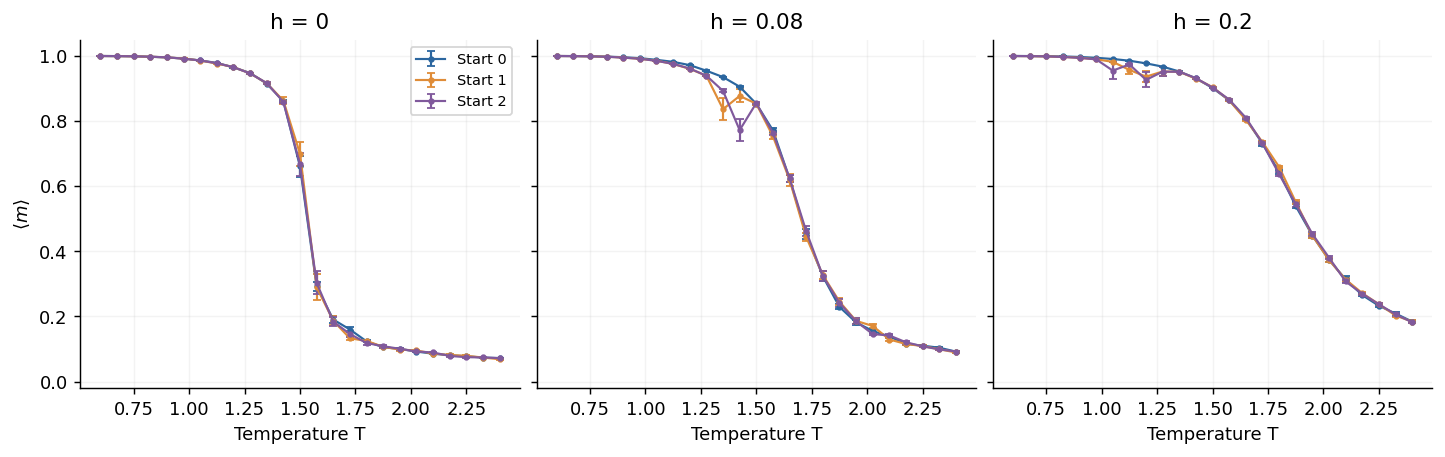

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True, constrained_layout=True)
for field_index, field in enumerate((0, .08, .20)):
    ax = axes[field_index]
    for state, color in enumerate(colors):
        draw_error(ax, runs[f'L24_h{field_index}_s{state}_m'], f'Start {state}', color)
    ax.set(title=f'h = {field:g}', xlabel='Temperature T', ylim=(-.02, 1.05))
    ax.grid(alpha=.15)
axes[0].set_ylabel(r'$\langle m\rangle$')
axes[0].legend(fontsize=8)
plt.show()


The original $h=1$, $L=50$ example used only four sweeps per temperature. Repeating it with four versus 500 sweeps shows that the dip depends on heating history. Each trajectory records one terminal configuration at each of 20 temperatures from 0.5 to 2.5; bars are SEM across eight trajectories.

Near $T=1.342$, the two protocols give magnitudes $0.463\pm0.006$ and $0.988\pm0.001$. Their corresponding horizontal components are approximately 0.186 and 0.988. The longer schedule realigns earlier; the short schedule loses magnitude during reorientation before recovering. This supports a kinetic interpretation, rather than evidence of another equilibrium phase transition.


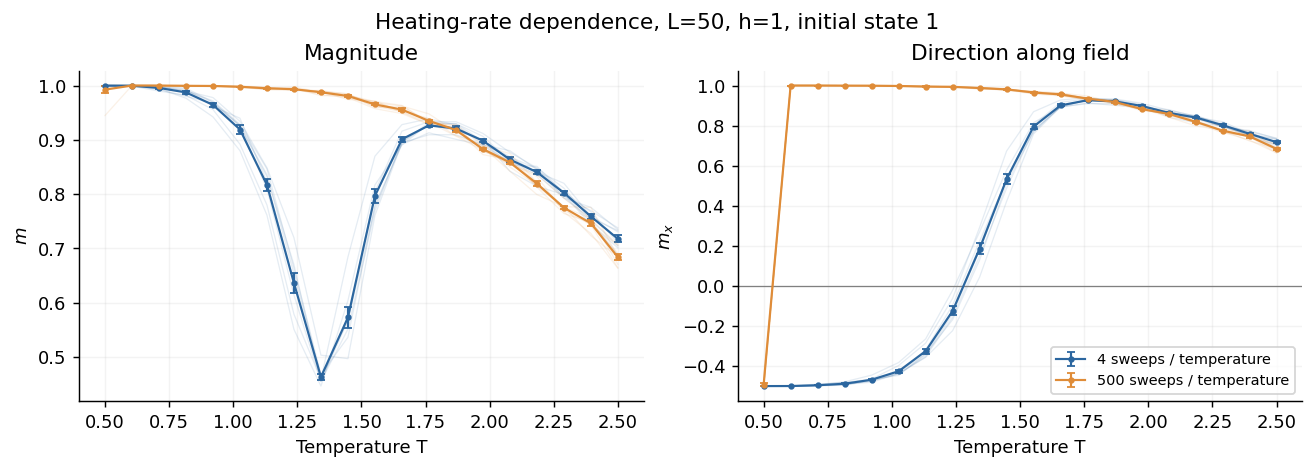

In [6]:
with np.load('results/switching_h1.npz') as data:
    switch_t = data['temperatures'].copy()
    switching = {name: data[name].copy() for name in ('short_m', 'short_mx', 'long_m', 'long_mx')}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for prefix, label, color in [('short', '4 sweeps / temperature', colors[0]),
                             ('long', '500 sweeps / temperature', colors[1])]:
    for ax, suffix in zip(axes, ('m', 'mx')):
        values = switching[f'{prefix}_{suffix}']
        for trajectory in values:
            ax.plot(switch_t, trajectory, color=color, alpha=.12, lw=.7)
        draw_error(ax, values, label, color, ts=switch_t)
for ax, title, ylabel in zip(axes, ('Magnitude', 'Direction along field'), (r'$m$', r'$m_x$')):
    ax.set(title=title, xlabel='Temperature T', ylabel=ylabel)
    ax.grid(alpha=.15)
axes[1].axhline(0, color='.5', lw=.7)
axes[1].legend(fontsize=8)
fig.suptitle('Heating-rate dependence, L=50, h=1, initial state 1')
plt.show()


## 7. Implementation checks

Both implementations are checked against exact enumeration below. Different random generators require statistical agreement, not identical trajectories. Timing uses equal work and excludes C++ compilation. The test suite additionally checks energy and magnetisation directly from snapshots, random starts and seeded reproducibility. Small-system agreement validates implementation, not equilibration of every larger simulation.

Runtime grows approximately with the number of attempted updates: lattice area times total sweeps times temperatures and repetitions. Compiled updates make the larger runs practical while keeping the Python implementation available for inspection. The measured speed ratio is specific to the displayed workload and machine.


In [7]:
# Enumerate all configurations; count each periodic bond once (right and down).
size, temperature, field = 3, 1.8, 0.3
vectors = reference_potts.SPINS
labels = (np.arange(3 ** (size * size))[:, None] //
          (3 ** np.arange(size * size))[None, :]) % 3
configs = labels.reshape(-1, size, size)
matches = ((configs == np.roll(configs, 1, axis=1)).sum(axis=(1, 2)) +
           (configs == np.roll(configs, 1, axis=2)).sum(axis=(1, 2)))
energy = -1.5 * matches - field * vectors[configs, 0].sum(axis=(1, 2))
magnetisation = np.linalg.norm(vectors[configs].mean(axis=(1, 2)), axis=1)
weights = np.exp(-(energy - energy.min()) / temperature)
exact_mean = np.average(magnetisation, weights=weights)
print(f'Exact enumeration: <m> = {exact_mean:.5f} (3^9 = {len(configs):,} states)')


Exact enumeration: <m> = 0.79710 (3^9 = 19,683 states)


In [8]:
try:
    import fast_potts
    # Compile/load before timing; one throwaway call also warms the native path.
    fast_potts.simulate([temperature], size=size, field=field, burn_sweeps=1,
                        samples=1, sample_interval=1, seed=42)
    fast_available = True
except (ImportError, RuntimeError, OSError) as error:
    fast_available = False
    print(f'C++ comparison skipped: {error}')

settings = dict(size=size, field=field, initial_state=0, burn_sweeps=300,
                samples=2500, sample_interval=1)

def compare_backend(backend, first_seed):
    started = perf_counter()
    means = []
    for seed in range(first_seed, first_seed + 8):
        chain = backend.simulate([temperature], seed=seed, **settings)
        means.append(chain['magnetisation'][0].mean())
    return np.array(means), perf_counter() - started

reference_means, python_time = compare_backend(reference_potts, 1000)
print(f'Python: {reference_means.mean():.5f} ± {reference_means.std(ddof=1)/np.sqrt(8):.5f}; '
      f'{python_time:.3f} s for 8 chains')
if fast_available:
    fast_means, cpp_time = compare_backend(fast_potts, 2000)
    print(f'C++:    {fast_means.mean():.5f} ± {fast_means.std(ddof=1)/np.sqrt(8):.5f}; '
          f'{cpp_time:.3f} s for 8 chains (compilation excluded)')
    print(f'This workload: {python_time/cpp_time:.1f}× speedup; results depend on hardware and workload.')
print(f'Environment: Python {platform.python_version()}, {platform.system()} {platform.machine()}')


Python: 0.79333 ± 0.00363; 3.671 s for 8 chains
C++:    0.79701 ± 0.00480; 0.008 s for 8 chains (compilation excluded)
This workload: 457.4× speedup; results depend on hardware and workload.
Environment: Python 3.12.14, Linux x86_64


### References

1. R. J. Baxter, “Potts model at the critical temperature,” *J. Phys. C* **6**, L445 (1973). [DOI](https://doi.org/10.1088/0022-3719/6/23/005).
2. J. F. Marko, “Cluster scaling geometry in critical spin systems,” *Phys. Rev. B* **45**, 5023 (1992). [DOI](https://doi.org/10.1103/PhysRevB.45.5023).
